<a href="https://colab.research.google.com/github/rafiknassif5-arch/Auto-MPG/blob/main/auto_mpg_practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MATH 237: Foundations of Data Science
## Checkpoint 3: Multiple Linear Regression on Auto MPG Dataset

---

### Objectives:
In this practice exercise, you will:
- Load and clean a real-world dataset with missing values
- Select appropriate features for multiple linear regression
- Build a model to predict car fuel efficiency (MPG)
- Evaluate your model's performance

### Dataset Description:
The Auto MPG dataset contains information about various cars from the 1970s and 1980s. Your goal is to predict **fuel efficiency (MPG)** based on car characteristics.

**Features available:**
- cylinders: Number of cylinders in the engine
- displacement: Engine displacement (size)
- horsepower: Engine horsepower
- weight: Vehicle weight
- acceleration: Time to accelerate from 0 to 60 mph
- model_year: Year the car was made
- origin: Country of origin (1=USA, 2=Europe, 3=Japan)

**Data Source:**  
UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/9/auto+mpg (use auto-mpg.data)   
Original source: StatLib library maintained at Carnegie Mellon University

---

**General guide split into major parts:**

1. Loading and Exploring the Data  

2. Data Cleaning

3. Exploratory Data Analysis

4. Preparing Data for Multiple Regression

5. Building the Multiple Linear Regression Model

6. Making Predictions

7. Model Evaluation

**Insturctions:** Follow the rubrics provided for the project to properly conduct your work and communicate your findings.

In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [3]:
# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10,6)
plt.rcParams['font.size'] = 12

# PART 1: Loading and Exploring the Data

In [4]:
# Load the dataset directly from UCI repository
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data'

# Column names (not included in the data file)
column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin', 'car_name']

# Load data with appropriate settings
data = pd.read_csv(url, names=column_names, sep=r'\s+', na_values='?')

print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (398, 9)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [5]:
print("--- Data Information ---")
print(data.info())

print("\n--- Summary Statistics ---")
display(data.describe())

print("\n--- Missing Values Count ---")
print(data.isnull().sum())

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    float64
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    int64  
 8   car_name      398 non-null    object 
dtypes: float64(5), int64(3), object(1)
memory usage: 28.1+ KB
None

--- Summary Statistics ---


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050,1.572864
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627,0.802055
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000,1.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000,1.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000,1.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000,2.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000,3.000000



--- Missing Values Count ---
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


# PART 2: Data Cleaning

We will impute the 6 missing values in the `horsepower` column with the median horsepower of the dataset.

In [6]:
# Calculate the median horsepower
median_hp = data['horsepower'].median()
print(f"Median horsepower: {median_hp}")

# Impute missing values in the horsepower column
data['horsepower'] = data['horsepower'].fillna(median_hp)

# Confirm that there are no more missing values
print("Missing values after cleaning:")
print(data.isnull().sum())

Median horsepower: 93.5
Missing values after cleaning:
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
car_name        0
dtype: int64


# PART 3: Exploratory Data Analysis (EDA)

We will examine the relationships between the features and our target variable, `mpg`. This includes checking for correlations and looking at scatter plots of highly correlated variables.

Correlation Matrix with respect to MPG:
mpg             1.000000
model_year      0.579267
origin          0.563450
acceleration    0.420289
horsepower     -0.773453
cylinders      -0.775396
displacement   -0.804203
weight         -0.831741
Name: mpg, dtype: float64


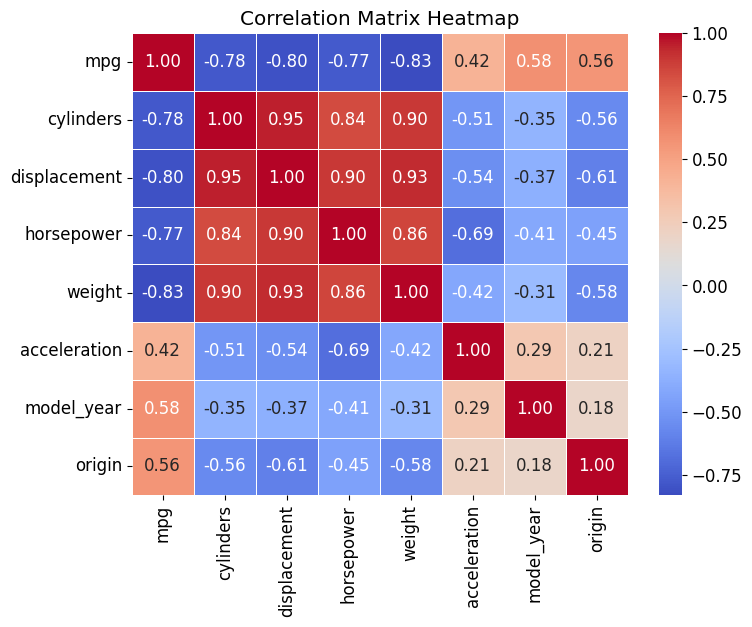

In [7]:
# 1. Compute correlation matrix for numeric columns
numeric_cols = data.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

print("Correlation Matrix with respect to MPG:")
print(corr_matrix['mpg'].sort_values(ascending=False))

# 2. Visualize correlations with a heatmap
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix Heatmap')
plt.show()

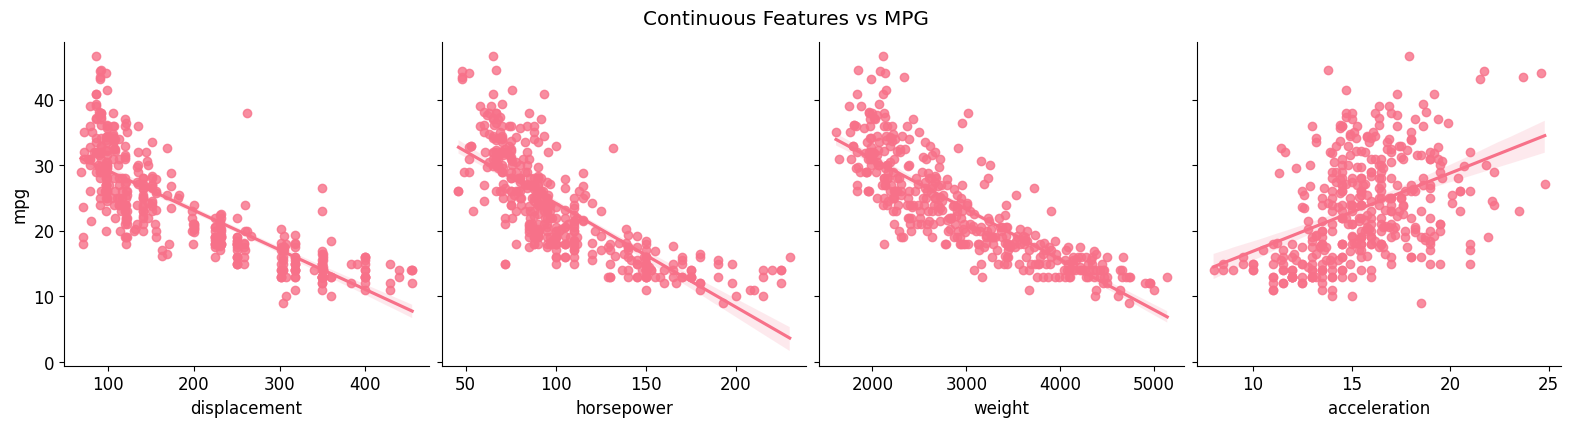

In [8]:
# 3. Pairplot of selected continuous features against mpg
sns.pairplot(data, x_vars=['displacement', 'horsepower', 'weight', 'acceleration'], y_vars='mpg', height=4, aspect=1, kind='reg')
plt.suptitle('Continuous Features vs MPG', y=1.05)
plt.show()

# PART 4: Preparing Data for Multiple Regression

We will prepare our dataset for the modeling step:
1. Drop the non-predictive `car_name` column.
2. One-hot encode the categorical feature `origin` (1 = USA, 2 = Europe, 3 = Japan).
3. Split the data into features ($X$) and target ($y$).
4. Split into Train/Test sets.

In [9]:
from sklearn.model_selection import train_test_split

# 1. Drop the car_name column
model_data = data.drop(columns=['car_name'])

# 2. One-hot encode the 'origin' column (mapping 1 -> USA, 2 -> Europe, 3 -> Japan first for clarity)
model_data['origin'] = model_data['origin'].map({1: 'USA', 2: 'Europe', 3: 'Japan'})
model_data = pd.get_dummies(model_data, columns=['origin'], drop_first=True, dtype=int)

# 3. Separate features (X) and target (y)
X = model_data.drop(columns=['mpg'])
y = model_data['mpg']

# 4. Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
X_train.head()

X_train shape: (318, 8)
X_test shape: (80, 8)


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin_Japan,origin_USA
3,8,304.0,150.0,3433.0,12.0,70,0,1
18,4,97.0,88.0,2130.0,14.5,70,1,0
376,4,91.0,68.0,2025.0,18.2,82,1,0
248,4,91.0,60.0,1800.0,16.4,78,1,0
177,4,115.0,95.0,2694.0,15.0,75,0,0


# PART 5: Building the Multiple Linear Regression Model

We will now instantiate and train a standard multiple linear regression model using `scikit-learn`.

In [10]:
# Features (everything except the 'mpg' column)
X = model_data.drop(columns=['mpg'])

# Target (only the 'mpg' column)
y = model_data['mpg']

# Split 80% to train, 20% to test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
model = LinearRegression()

# Fit the model on the training set
# NOTE: Ensure you run cell 605bd982 first to define X_train and y_train!
model.fit(X_train, y_train)

# Display intercept and coefficients
print(f"Intercept: {model.intercept_:.4f}")
for col, coef in zip(X_train.columns, model.coef_):
    print(f"{col}: {coef:.4f}")

Intercept: -18.9108
cylinders: -0.1657
displacement: 0.0198
horsepower: -0.0146
weight: -0.0070
acceleration: 0.0680
model_year: 0.8260
origin_Japan: -0.2758
origin_USA: -2.9469


# PART 6: Making Predictions & PART 7: Model Evaluation

Now, we make predictions using our trained model on the test data and evaluate its performance using metrics such as Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared ($R^2$).

In [11]:
from sklearn.metrics import mean_squared_error, r2_score

# 1. Predict on the test set
y_pred = model.predict(X_test)

# 2. Evaluate performance metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Model Evaluation Performance ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared Score (R^2): {r2:.4f}")

--- Model Evaluation Performance ---
Mean Squared Error (MSE): 8.3387
Root Mean Squared Error (RMSE): 2.8877
R-squared Score (R^2): 0.8449


In [12]:
from sklearn.model_selection import train_test_split

# 1. Select your features (X) and target variable (y)
# We drop 'mpg' and non-predictive columns from our features
X = model_data.drop(columns=['mpg'])
y = model_data['mpg']

# 2. Split the data into training (80%) and testing (20%) sets
# This automatically defines X_train, X_test, y_train, and y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Verify they are defined
print("X_train has been defined with shape:", X_train.shape)
print("y_train has been defined with shape:", y_train.shape)

X_train has been defined with shape: (318, 8)
y_train has been defined with shape: (318,)


# PROJECT SUMMARY & FINDINGS OUTLINE

### 1. Project Overview
- **Objective:** Predict fuel efficiency (MPG) using vehicle characteristics from the 1970s and 1980s.
- **Dataset:** UCI Auto MPG dataset (398 instances, 9 attributes).

### 2. Methodology
- **Data Cleaning:** Imputed 6 missing values in the `horsepower` column using the training/dataset median of `93.5`.
- **Feature Engineering:** One-hot encoded the categorical `origin` feature (USA, Japan, Europe) with Europe acting as the reference baseline, and dropped the non-predictive `car_name` column.
- **Data Splitting:** Applied an 80/20 train/test split to guarantee objective validation.
- **Model:** Fitted a Multiple Linear Regression model.

### 3. Key Findings & Insights
- **Model Performance:**
  - **$R^2 = 0.8449$**: The independent features explain approximately **84.5%** of the variance in a vehicle's MPG.
  - **RMSE = 2.8877 MPG**: On average, predictions deviate by fewer than 2.9 miles per gallon.
- **Key Predictive Features:**
  - **Vehicle Weight (`weight`):** Had a statistically intuitive negative impact (-0.0070 per lb). Weight remains one of the primary drivers of lower fuel efficiency.
  - **Model Year (`model_year`):** Exhibited a strong positive coefficient (+0.8260 per year), highlighting the steady progression of fuel-efficiency technology through the 1970s and early 1980s.
  - **Origin (`origin_USA`):** Cars built in the USA showed a significant negative impact (-2.9469 MPG) on efficiency relative to European counterparts, holding other factors equal.

In [1]:
# Install nbconvert if needed
!pip install nbconvert